# Advanced models
**Report section:** Open-ended improvements (15 pts)

In [9]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

QUICK = False  # True = 2,000-row debug run, False = full data (use for the report)

In [10]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split, load_test, xy
from src.models import make_model
from src.evaluate import auroc, log_result, savefig, save_predictions
set_seed(SEED)

## Data
Already cleaned by `src/data.py` (encoding fixes + NFC). Everyone on the team uses the same split: 8,000 train / 2,000 val, stratified, seed 42.

Best model going into this notebook: `robust_svm_tuned_blank` (val 0.991, Kaggle public 0.913). For reference, `baseline` got val 0.956 and Kaggle 0.860.

In [11]:
train_df, val_df = get_split(quick=QUICK)   # 8,000 / 2,000 rows, 50% AI each
test_df = load_test()                        # 3,000 rows (never dropped)
X_tr, y_tr = xy(train_df)
X_va, y_va = xy(val_df)

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True
[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


## What I'm trying here
We already got a big jump from removing formatting (`robust_*`, Kaggle 0.860 to 0.897) and from the blank-line boost (0.913). Everything below gets compared to `robust_svm_tuned_blank` on the same val set.

Done below:
- MLP and boosted MLP on `TruncatedSVD(300)` of the robust features
- DistilRoBERTa, on its own and ensembled with the SVM

Haven't tried these here yet:
- Stacking: LogReg on out-of-fold SVM scores + format flags (blank lines, ends mid-sentence, double spaces, etc.)
- Data augmentation: typo'd / contracted copies of the AI train texts
- Self-training with the SVM on `unlabeled.csv` (not test.csv)

## Boosting small neural nets
Can boosting a bunch of small neural nets beat one regular MLP? And does it add anything on top of the SVM?

**How it works:** the text goes through the same tuned TF-IDF features as `robust_svm_tuned`, then `TruncatedSVD(300)` and scaling, since an MLP can't really train on millions of sparse columns. Each round trains a small `MLPRegressor` on the logistic-loss residuals `y - sigmoid(F)` using a random 80% of the rows, then adds a shrunken version of it to the score `F`.

**Keeping it fair:** I never use the 2,000 val rows to pick anything. The settings and number of rounds come from a 10% holdout inside the 8,000 training rows, and every model gets the same features.

In [12]:
import warnings
from scipy.stats import spearmanr
from sklearn.decomposition import TruncatedSVD
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from src.evaluate import rank_average, write_submission
from src.features import has_blank_line_breaks

warnings.filterwarnings("ignore", category=ConvergenceWarning)
N_ROUNDS = 5 if QUICK else 40
PUSH = 0.1  # same blank-line push as robust_svm_tuned_blank; not retuned here


def sigmoid(f):
    return 1.0 / (1.0 + np.exp(-f))


class BoostedMLP:
    """Gradient boosting with logistic loss, using small MLP regressors as weak learners."""

    def __init__(self, n_rounds=40, lr=0.3, hidden=(64,), alpha=1e-3, subsample=0.8, max_iter=15, seed=SEED):
        self.n_rounds, self.lr, self.hidden, self.alpha = n_rounds, lr, hidden, alpha
        self.subsample, self.max_iter, self.seed = subsample, max_iter, seed

    def fit(self, Z, y, Z_mon=None, y_mon=None):
        y = np.asarray(y, float)
        r = np.random.default_rng(self.seed)
        self.learners_, self.monitor_ = [], []
        F = np.zeros(len(y))
        F_mon = None if Z_mon is None else np.zeros(len(Z_mon))
        for m in range(self.n_rounds):
            idx = r.choice(len(y), int(self.subsample * len(y)), replace=False)
            h = MLPRegressor(hidden_layer_sizes=self.hidden, alpha=self.alpha, batch_size=128,
                             max_iter=self.max_iter, random_state=self.seed + m)
            h.fit(Z[idx], y[idx] - sigmoid(F[idx]))
            self.learners_.append(h)
            F += self.lr * h.predict(Z)
            if F_mon is not None:
                F_mon += self.lr * h.predict(Z_mon)
                self.monitor_.append(auroc(y_mon, F_mon))
        return self

    def decision_function(self, Z, n_rounds=None):
        return self.lr * np.sum([h.predict(Z) for h in self.learners_[:n_rounds]], axis=0)

    def predict_proba1(self, Z, n_rounds=None):
        return sigmoid(self.decision_function(Z, n_rounds))


def embedder():
    return Pipeline([("tfidf", make_model("robust_svm_tuned").named_steps["features"]),
                     ("svd", TruncatedSVD(300, random_state=SEED)), ("scale", StandardScaler())])


def blank_push(p, texts):
    b = np.array([has_blank_line_breaks(t) for t in texts], dtype=float)
    return (p + PUSH * b) / (1 + PUSH)


t0 = time.time()
emb = embedder()
Z_tr = emb.fit_transform(X_tr)
Z_va = emb.transform(X_va)
embed_s = time.time() - t0
inner_fit, inner_hold = train_test_split(np.arange(len(y_tr)), test_size=0.1, stratify=y_tr, random_state=SEED)
print(f"embedded in {embed_s:.0f}s, shape {Z_tr.shape}, SVD variance kept {emb.named_steps['svd'].explained_variance_ratio_.sum():.3f}")
print(f"inner fit {len(inner_fit)}, inner holdout {len(inner_hold)}")

embedded in 8516s, shape (8000, 300), SVD variance kept 0.140
inner fit 7200, inner holdout 800


### One MLP (the baseline to beat)
Tuned on the inner holdout.

In [13]:
rows = []
for hidden in [(128,), (256, 64)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        t0 = time.time()
        m = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, batch_size=128, max_iter=100, early_stopping=True,
                          n_iter_no_change=5, random_state=SEED).fit(Z_tr[inner_fit], y_tr[inner_fit])
        rows.append({"hidden": hidden, "alpha": alpha, "inner_auroc": auroc(y_tr[inner_hold], m.predict_proba(Z_tr[inner_hold])[:, 1]),
                     "fit_s": round(time.time() - t0, 1)})
mlp_grid = pd.DataFrame(rows).sort_values("inner_auroc", ascending=False)
if not QUICK:
    mlp_grid.to_csv(RESULTS_DIR / "nn_mlp_grid.csv", index=False)
mlp_best = mlp_grid.iloc[0]
mlp_grid.round(4)

,hidden,alpha,inner_auroc,fit_s
5,"(256, 64)",1.0000,0.9654,3.7
1,"(128,)",0.0100,0.9643,1.4
2,"(128,)",1.0000,0.9637,1.2
0,"(128,)",0.0001,0.9630,1.2
3,"(256, 64)",0.0001,0.9612,3.1
4,"(256, 64)",0.0100,0.9581,2.2


### Boosted MLP
Picking the settings and number of rounds on the inner holdout.

,hidden,lr,best_round,inner_auroc,first_round_auroc,fit_s
2,"(64,)",0.3,38,0.9632,0.842,28.6
0,"(32,)",0.3,28,0.9573,0.858,21.2
3,"(64,)",1.0,12,0.9422,0.842,28.1
1,"(32,)",1.0,28,0.9260,0.858,21.4


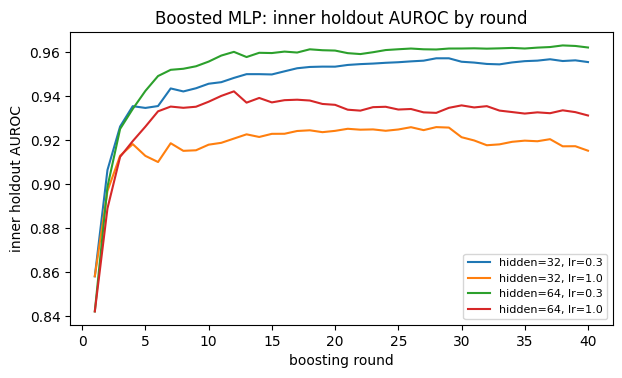

In [14]:
rows, curves = [], {}
for hidden in [(32,), (64,)]:
    for lr in [0.3, 1.0]:
        t0 = time.time()
        b = BoostedMLP(N_ROUNDS, lr, hidden).fit(Z_tr[inner_fit], y_tr[inner_fit], Z_tr[inner_hold], y_tr[inner_hold])
        best = int(np.argmax(b.monitor_)) + 1
        key = f"hidden={hidden[0]}, lr={lr}"
        curves[key] = b.monitor_
        rows.append({"hidden": hidden, "lr": lr, "best_round": best, "inner_auroc": max(b.monitor_), "first_round_auroc": b.monitor_[0],
                     "fit_s": round(time.time() - t0, 1)})
boost_grid = pd.DataFrame(rows).sort_values("inner_auroc", ascending=False)
boost_best = boost_grid.iloc[0]
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, c in curves.items():
    ax.plot(range(1, len(c) + 1), c, label=k)
ax.set(xlabel="boosting round", ylabel="inner holdout AUROC", title="Boosted MLP: inner holdout AUROC by round")
ax.legend(fontsize=8)
if not QUICK:
    boost_grid.to_csv(RESULTS_DIR / "nn_boost_grid.csv", index=False)
    savefig(fig, "nn_boost_rounds")
boost_grid.round(4)

### Comparing on val
Refit the best settings on all 8,000 training rows, then score once on the shared val set.

In [15]:
def fit_final_boost(Z, y):
    return BoostedMLP(int(boost_best.best_round), float(boost_best.lr), tuple(boost_best.hidden)).fit(Z, y)

t0 = time.time()
mlp = MLPClassifier(hidden_layer_sizes=tuple(mlp_best.hidden), alpha=float(mlp_best.alpha), batch_size=128, max_iter=100,
                    early_stopping=True, n_iter_no_change=5, random_state=SEED).fit(Z_tr, y_tr)
mlp_s = time.time() - t0
t0 = time.time()
boost = fit_final_boost(Z_tr, y_tr)
boost_s = time.time() - t0

p_tr_mlp, p_va_mlp = mlp.predict_proba(Z_tr)[:, 1], mlp.predict_proba(Z_va)[:, 1]
p_tr_b, p_va_b = boost.predict_proba1(Z_tr), boost.predict_proba1(Z_va)
p_va_b_blank = blank_push(p_va_b, X_va)

def saved(name, split, ids):
    d = pd.read_csv(RESULTS_DIR / f"preds_{name}.csv")
    return d[d.split == split].set_index("id").loc[ids, "prob"].to_numpy()

rows = [{"model": "single MLP", "train_auroc": auroc(y_tr, p_tr_mlp), "val_auroc": auroc(y_va, p_va_mlp), "fit_s": round(embed_s + mlp_s, 1)},
        {"model": "boosted MLP", "train_auroc": auroc(y_tr, p_tr_b), "val_auroc": auroc(y_va, p_va_b), "fit_s": round(embed_s + boost_s, 1)},
        {"model": "boosted MLP + blank-line push", "train_auroc": auroc(y_tr, blank_push(p_tr_b, X_tr)), "val_auroc": auroc(y_va, p_va_b_blank), "fit_s": round(embed_s + boost_s, 1)}]
if not QUICK:
    p_va_svm, p_va_svm_blank = saved("robust_svm_tuned", "val", val_df["id"]), saved("robust_svm_tuned_blank", "val", val_df["id"])
    rows += [{"model": "robust_svm_tuned (saved)", "val_auroc": auroc(y_va, p_va_svm)},
             {"model": "robust_svm_tuned_blank (saved)", "val_auroc": auroc(y_va, p_va_svm_blank)},
             {"model": "rank average: SVM + boosted MLP, no blank push", "val_auroc": auroc(y_va, rank_average([p_va_svm, p_va_b]))},
             {"model": "rank average: SVM blank + boosted MLP blank", "val_auroc": auroc(y_va, rank_average([p_va_svm_blank, p_va_b_blank]))}]
nn_table = pd.DataFrame(rows)
if not QUICK:
    nn_table.to_csv(RESULTS_DIR / "nn_boost_comparison.csv", index=False)
    log_result("nn_boost", {"model": "BoostedMLP", "hidden": str(boost_best.hidden), "lr": float(boost_best.lr), "rounds": int(boost_best.best_round),
                            "svd": 300, "push": PUSH}, {"val_auroc": auroc(y_va, p_va_b), "val_auroc_blank": auroc(y_va, p_va_b_blank)})
nn_table.round(4)

,model,train_auroc,val_auroc,fit_s
0,single MLP,0.998,0.9715,8519.0
1,boosted MLP,1.000,0.9724,8545.4
2,boosted MLP + blank-line push,1.000,0.9829,8545.4
3,robust_svm_tuned (saved),NaN,0.9786,NaN
4,robust_svm_tuned_blank (saved),NaN,0.9905,NaN
5,"rank average: SVM + boosted MLP, no blank push",NaN,0.9790,NaN
6,rank average: SVM blank + boosted MLP blank,NaN,0.9894,NaN


### Test predictions
Refit on all 10,000 labeled rows. No test text gets used for fitting. This only writes the files, uploading to Kaggle is still manual.

In [16]:
if QUICK:
    print("QUICK run: skipping the full refit and test files")
else:
    X_all = list(X_tr) + list(X_va)
    y_all = np.r_[y_tr, y_va]
    X_te = test_df["text"].tolist()
    t0 = time.time()
    emb_all = embedder()
    Z_all = emb_all.fit_transform(X_all)
    Z_te = emb_all.transform(X_te)
    boost_all = fit_final_boost(Z_all, y_all)
    p_te_b = boost_all.predict_proba1(Z_te)
    p_te_blank = blank_push(p_te_b, X_te)
    print(f"final refit and test prediction: {time.time() - t0:.0f}s")

    save_predictions("nn_boost", val_df, p_va_b, test_df, p_te_b)
    save_predictions("nn_boost_blank", val_df, p_va_b_blank, test_df, p_te_blank)

    t_svm, t_svm_blank = saved("robust_svm_tuned", "test", test_df["id"]), saved("robust_svm_tuned_blank", "test", test_df["id"])
    print("test rank correlation, boosted MLP vs SVM:", round(spearmanr(p_te_b, t_svm).statistic, 4))
    print("val rank correlation, boosted MLP vs SVM:", round(spearmanr(p_va_b, p_va_svm).statistic, 4))
    print("test mean P(AI):", round(float(p_te_b.mean()), 3), " share above 0.5:", round(float((p_te_b >= .5).mean()), 3))
    write_submission(test_df, p_te_blank, tag="nn_boost_blank")
    write_submission(test_df, rank_average([t_svm_blank, p_te_blank]), tag="svm_blank_plus_nn_boost")

final refit and test prediction: 322s
saved results\preds_nn_boost.csv
saved results\preds_nn_boost_blank.csv
test rank correlation, boosted MLP vs SVM: 0.9291
val rank correlation, boosted MLP vs SVM: 0.9451
test mean P(AI): 0.422  share above 0.5: 0.355
wrote submissions\submission_20261109_220840_nn_boost_blank.csv (3000 rows) - validated OK
wrote submissions\submission_20261109_220840_svm_blank_plus_nn_boost.csv (3000 rows) - validated OK


## Transformer (DistilRoBERTa) + ensemble
Does a model that actually reads whole sentences hold up better on the test set than TF-IDF? And does it add anything to the SVM?

**How it works:** the text gets the same cleaning as the `robust_*` models (no line breaks, straight quotes, one dash style) so the transformer can't just learn the blank-line shortcut. I pick the number of epochs on a 10% holdout inside the 8,000 training rows, refit on those 8,000 and score once on val, then refit on all 10,000 for the test predictions.

**Running it on Kaggle:** these cells need a GPU and don't use `src/`, so they run without the rest of the notebook. (IF YOU HAVE NOT USED KAGGLE BEFORE READ THIS!!!!)
1. On Kaggle: Create > New Notebook, then File > Import Notebook and pick this file.
2. Add Input: attach the competition data, and upload `data/split_ids.json` as a small private dataset.
3. Settings: Accelerator = GPU, Internet = on. (IMPORTANT!! DO NOT SKIP THIS!!)
4. Click into the "Transformer setup" cell and run it and the next two cells with Shift+Enter. **Do not use Run All**, the earlier cells need `src/`.
5. From the Output panel, download `preds_transformer.csv` into `results/` and `submission_transformer.csv` into `submissions/`. You can upload `submission_transformer.csv` straight to Kaggle to see the transformer alone.
6. Back on your computer, run the "Transformer ensemble" cell.

In [ ]:
# Transformer setup (runs on Kaggle by itself, doesn't need src/ or anything above)
import os, re, subprocess, sys, time
from pathlib import Path
import json as tf_json
import numpy as np, pandas as pd

TF_DATA_DIR = Path(os.environ.get("TF_DATA_DIR", "/kaggle/input"))
RUN_TRANSFORMER = TF_DATA_DIR.is_dir()

TF_MODEL = "distilroberta-base"
TF_SMOKE = False    # True = 200 rows, 1 epoch, just to check it runs
TF_EPOCHS = 1 if TF_SMOKE else 3
TF_MAX_LEN = 320    # tokens; texts average about 200 words
TF_BATCH = 16
TF_LR = 2e-5
TF_SEED = 42
TF_OUT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()

if not RUN_TRANSFORMER:
    print("No Kaggle data folder here: skipping transformer training.")
else:
    try:
        import ftfy
    except ImportError:
        # ftfy is nice to have, training still works without it
        import importlib
        tf_pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ftfy"], capture_output=True, text=True)
        importlib.invalidate_caches()
        try:
            import ftfy
        except ImportError:
            ftfy = None
            print("ftfy not installed, so encoding repair is off. pip said:", (tf_pip.stderr or tf_pip.stdout)[-400:])
    import torch
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import train_test_split
    from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                              get_linear_schedule_with_warmup)

    try:
        AutoTokenizer.from_pretrained(TF_MODEL)
    except Exception as e:
        raise RuntimeError("Could not download the model. On Kaggle, turn Internet on in Settings, then run this cell again.") from e

    tf_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tf_amp = tf_device.type == "cuda"
    print("device:", tf_device)
    if not tf_amp and not TF_SMOKE:
        print("WARNING: no GPU found. Turn on the GPU in Settings, or this will take many hours.")

    tf_quotes = str.maketrans({"“": '"', "”": '"', "‘": "'", "’": "'"})

    def tf_clean(text):
        # same cleaning as src/data.clean_text + normalize_style
        if ftfy is not None:
            text = ftfy.fix_text(text, unescape_html=False, fix_latin_ligatures=False, fix_character_width=False,
                                 uncurl_quotes=False, fix_line_breaks=False, normalization="NFC")
        text = re.sub(r"\s*(—|–|--)\s*", " - ", text.translate(tf_quotes))
        return re.sub(r"\s+", " ", text).strip()

    def tf_find(name):
        hits = sorted(TF_DATA_DIR.rglob(name))
        if not hits:
            raise FileNotFoundError(f"{name} not found under {TF_DATA_DIR}. Check Add Input (step 2 above).")
        return hits[0]

    def tf_read(name):
        d = pd.read_csv(tf_find(name), keep_default_na=False, dtype={"text": str})
        d["clean"] = d["text"].map(tf_clean)
        return d

    tf_train_all = tf_read("train.csv")
    tf_test = tf_read("test.csv")
    tf_split = tf_json.loads(tf_find("split_ids.json").read_text())
    tf_train = tf_train_all[tf_train_all["id"].isin(set(tf_split["train_ids"]))].reset_index(drop=True)
    tf_val = tf_train_all[tf_train_all["id"].isin(set(tf_split["val_ids"]))].reset_index(drop=True)
    if TF_SMOKE:
        tf_train = tf_train.sample(200, random_state=TF_SEED).reset_index(drop=True)
        tf_val = tf_val.sample(100, random_state=TF_SEED).reset_index(drop=True)
        tf_train_all = pd.concat([tf_train, tf_val], ignore_index=True)
        tf_test = tf_test.head(50).copy()
    print(f"train {len(tf_train)}, val {len(tf_val)}, all labeled {len(tf_train_all)}, test {len(tf_test)}")

In [ ]:
# Transformer training + picking the number of epochs (inner holdout only, never val)
if RUN_TRANSFORMER:
    tf_tok = AutoTokenizer.from_pretrained(TF_MODEL)
    tf_collate = DataCollatorWithPadding(tf_tok)

    def tf_items(texts, labels=None):
        enc = tf_tok(list(texts), truncation=True, max_length=TF_MAX_LEN)
        rows = [{k: enc[k][i] for k in enc} for i in range(len(enc["input_ids"]))]
        if labels is not None:
            for row, lab in zip(rows, labels):
                row["labels"] = int(lab)
        return rows

    def tf_predict(model, items):
        model.eval()
        out = []
        with torch.no_grad():
            for b in torch.utils.data.DataLoader(items, batch_size=TF_BATCH * 2, shuffle=False, collate_fn=tf_collate):
                b = {k: v.to(tf_device) for k, v in b.items() if k != "labels"}
                with torch.autocast(tf_device.type, enabled=tf_amp):
                    logits = model(**b).logits
                out.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy())
        return np.concatenate(out)

    def tf_fit(items, epochs, mon_items=None, mon_y=None):
        torch.manual_seed(TF_SEED)
        model = AutoModelForSequenceClassification.from_pretrained(TF_MODEL, num_labels=2).to(tf_device)
        loader = torch.utils.data.DataLoader(items, batch_size=TF_BATCH, shuffle=True, collate_fn=tf_collate,
                                             generator=torch.Generator().manual_seed(TF_SEED))
        opt = torch.optim.AdamW(model.parameters(), lr=TF_LR, weight_decay=0.01)
        steps = epochs * len(loader)
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        scaler = torch.amp.GradScaler(tf_device.type, enabled=tf_amp)
        history = []
        for ep in range(1, epochs + 1):
            model.train()
            t0, total = time.time(), 0.0
            for b in loader:
                b = {k: v.to(tf_device) for k, v in b.items()}
                opt.zero_grad(set_to_none=True)
                with torch.autocast(tf_device.type, enabled=tf_amp):
                    loss = model(**b).loss
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sched.step()
                total += loss.item()
            rec = {"epoch": ep, "train_loss": round(total / len(loader), 4), "seconds": round(time.time() - t0)}
            if mon_items is not None:
                rec["inner_auroc"] = round(float(roc_auc_score(mon_y, tf_predict(model, mon_items))), 4)
            history.append(rec)
            print(rec)
        return model, history

    tf_y = tf_train["label"].to_numpy()
    tf_fit_idx, tf_hold_idx = train_test_split(np.arange(len(tf_y)), test_size=0.1, stratify=tf_y, random_state=TF_SEED)
    tf_all_items = tf_items(tf_train["clean"], tf_y)
    _, tf_history = tf_fit([tf_all_items[i] for i in tf_fit_idx], TF_EPOCHS,
                           [tf_all_items[i] for i in tf_hold_idx], tf_y[tf_hold_idx])
    tf_best_epochs = int(pd.DataFrame(tf_history).sort_values("inner_auroc", ascending=False).iloc[0]["epoch"])
    print("best number of epochs on the inner holdout:", tf_best_epochs)

In [ ]:
# Refit with the best epochs: 8,000 rows for val, then all 10,000 for test
if RUN_TRANSFORMER:
    tf_model, _ = tf_fit(tf_all_items, tf_best_epochs)
    tf_train_p = tf_predict(tf_model, tf_all_items)
    tf_val_p = tf_predict(tf_model, tf_items(tf_val["clean"], tf_val["label"]))
    print("train AUROC:", round(float(roc_auc_score(tf_y, tf_train_p)), 4))
    print("val AUROC:  ", round(float(roc_auc_score(tf_val["label"], tf_val_p)), 4))

    del tf_model
    if tf_amp:
        torch.cuda.empty_cache()
    tf_model, _ = tf_fit(tf_items(tf_train_all["clean"], tf_train_all["label"]), tf_best_epochs)
    tf_test_p = tf_predict(tf_model, tf_items(tf_test["clean"]))

    if not TF_SMOKE:
        assert len(tf_val_p) == 2000 and len(tf_test_p) == 3000, "unexpected row counts"
    assert np.isfinite(tf_val_p).all() and np.isfinite(tf_test_p).all(), "predictions contain NaN/inf"

    pd.concat([pd.DataFrame({"id": tf_val["id"], "split": "val", "label": tf_val["label"], "prob": tf_val_p}),
               pd.DataFrame({"id": tf_test["id"], "split": "test", "label": np.nan, "prob": tf_test_p})],
              ignore_index=True).to_csv(TF_OUT / "preds_transformer.csv", index=False, float_format="%.6f")
    pd.DataFrame({"id": tf_test["id"], "label": tf_test_p}).to_csv(TF_OUT / "submission_transformer.csv", index=False,
                                                                   float_format="%.6f")
    print("wrote preds_transformer.csv and submission_transformer.csv to", TF_OUT)

### Transformer ensemble
Run this one on your computer once `preds_transformer.csv` is in `results/`. It only needs the first two code cells of this notebook. The 0.1 blank-line push is the same one `robust_svm_tuned_blank` uses. The val numbers here still have the blank-line shortcut in them, so go by Kaggle for these.

In [17]:
# Transformer ensemble: run this on your computer, not Kaggle. Compares on val and writes 2 submissions
from src.config import RESULTS_DIR as TF_RESULTS
from src.data import get_split as tf_get_split, load_test as tf_load_test
from src.evaluate import auroc as tf_auroc, rank_average as tf_rank, write_submission as tf_write
from src.features import has_blank_line_breaks as tf_blank

tf_preds_file = TF_RESULTS / "preds_transformer.csv"
if not tf_preds_file.exists():
    print(f"{tf_preds_file.name} not found in results/: finish in kaggle first!")
else:
    _, tf_val_df = tf_get_split(quick=False, verbose=False)
    tf_test_df = tf_load_test(verbose=False)
    tf_y_va = tf_val_df["label"].to_numpy()

    def tf_get(path, split, ids):
        d = pd.read_csv(path)
        return d[d["split"] == split].set_index("id").loc[ids, "prob"].to_numpy()

    def tf_push(p, texts, push=0.1):
        b = np.array([tf_blank(t) for t in texts], dtype=float)
        return (p + push * b) / (1 + push)

    v_ids, t_ids = tf_val_df["id"], tf_test_df["id"]
    v_tf, t_tf = tf_get(tf_preds_file, "val", v_ids), tf_get(tf_preds_file, "test", t_ids)
    v_tf_b, t_tf_b = tf_push(v_tf, tf_val_df["text"]), tf_push(t_tf, tf_test_df["text"])
    v_svm, t_svm_b = (tf_get(TF_RESULTS / "preds_robust_svm_tuned_blank.csv", s, i) for s, i in (("val", v_ids), ("test", t_ids)))
    v_nn, t_nn_b = (tf_get(TF_RESULTS / "preds_nn_boost_blank.csv", s, i) for s, i in (("val", v_ids), ("test", t_ids)))

    display(pd.DataFrame([
        {"model": "transformer, no blank push", "val_auroc": tf_auroc(tf_y_va, v_tf)},
        {"model": "transformer + blank push", "val_auroc": tf_auroc(tf_y_va, v_tf_b)},
        {"model": "robust_svm_tuned_blank", "val_auroc": tf_auroc(tf_y_va, v_svm)},
        {"model": "rank average: SVM + transformer", "val_auroc": tf_auroc(tf_y_va, tf_rank([v_svm, v_tf_b]))},
        {"model": "rank average: SVM + boosted MLP + transformer", "val_auroc": tf_auroc(tf_y_va, tf_rank([v_svm, v_nn, v_tf_b]))},
    ]).round(4))

    tf_write(tf_test_df, tf_rank([t_svm_b, t_tf_b]), tag="svm_blank_plus_transformer")
    tf_write(tf_test_df, tf_rank([t_svm_b, t_nn_b, t_tf_b]), tag="svm_nn_boost_transformer")

,model,val_auroc
0,"transformer, no blank push",0.9849
1,transformer + blank push,0.9906
2,robust_svm_tuned_blank,0.9905
3,rank average: SVM + transformer,0.9949
4,rank average: SVM + boosted MLP + transformer,0.9946


wrote submissions\submission_20261109_232020_svm_blank_plus_transformer.csv (3000 rows) - validated OK
wrote submissions\submission_20261109_232020_svm_nn_boost_transformer.csv (3000 rows) - validated OK
